# Fig. 5b, 5c, 5g with the Cristiano-free encoder

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

Reviewer 2.M1: the Cristiano et al. cohort is in both the pretraining corpus and the
Fig. 5 benchmark. These are Fig. 5b, 5c and 5g redrawn from the MIL predictions of the
encoder pretrained without any Cristiano sample, at **10,000 fragments per sample**.
Published Fig. 5 is at 100,000 fragments (pan-cancer AUC 0.95), so these panels must not
be compared with it; the depth-matched comparison with the released encoder is
`cfdna_nocristiano_paired.ipynb`.

Plotting code is copied from `src/cfdna/fig5_no_cristiano/make_fig5bc.py` (itself from
`cfdna_mil_detection.ipynb`) and `make_fig5g.py` (from `cfdna_ctdna_detection.ipynb`).
The per-task AUC table behind 5c is computed here from the predictions: pooled
`prob_ensemble` AUC, 1,000 bootstrap resamples, seed 42. ctDNA tertiles come from the
ichorCNA tumor fraction and do not depend on the model.

Fig. 5d-f are not redrawn: no subsampling runs exist for this encoder, and 5f compares
with DELFI at 100,000 fragments.

Panels:
- `cfdna_nocristiano_pan_cancer_roc` (Fig. 5b, pan-cancer ROC)
- `cfdna_nocristiano_per_cancer_auc` (Fig. 5c, per-cancer AUC vs healthy / vs other cancers)
- `cfdna_nocristiano_ctdna_logit_forest` (Fig. 5g, median logit probability by ctDNA tertile)

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: cfdna/data
OUT : cfdna/output


In [2]:
# ── Data ──────────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans', 'Helvetica'],
    'font.size': 7, 'axes.titlesize': 8, 'axes.labelsize': 7,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 6,
    'axes.linewidth': 0.5, 'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'lines.linewidth': 1, 'figure.dpi': 150, 'savefig.dpi': 600,
    'savefig.bbox': 'tight', 'axes.spines.top': False, 'axes.spines.right': False,
})

# Already deduplicated on (sample_id, task) and without Duodenal/Unknown (see stage_data.py).
df = pd.read_csv(DATA / "cfdna_nocristiano_mil_predictions.csv", float_precision="round_trip")
assert len(df) == 4178 and not df.duplicated(['sample_id', 'task']).any()
print(f'{len(df)} predictions, {df.task.nunique()} tasks')

4178 predictions, 15 tasks


saved: cfdna/output/cfdna_nocristiano_pan_cancer_roc.pdf
saved: cfdna/output/cfdna_nocristiano_pan_cancer_roc.png
saved: cfdna/output/cfdna_nocristiano_pan_cancer_roc.svg
saved: cfdna/output/cfdna_nocristiano_pan_cancer_roc.tsv


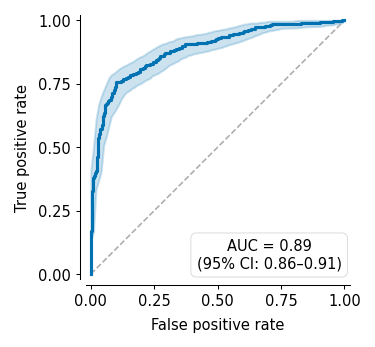

5b pan-cancer AUC 0.8873 [0.8582, 0.9131] n=535 pos=275


In [3]:
# ── Fig. 5b: pan-cancer ROC ───────────────────────────────────────────────────
df_pan = df[df['task'] == 'cancer_vs_healthy'].copy(); y_true = df_pan['label'].values; y_prob = df_pan['prob_ensemble'].values
fpr_main, tpr_main, _ = roc_curve(y_true, y_prob); auc_value = roc_auc_score(y_true, y_prob)
rng = np.random.default_rng(42); fpr_grid = np.linspace(0, 1, 100); tpr_boot = []; auc_boot = []
for _ in range(1000):
    idx = rng.choice(len(y_true), size=len(y_true), replace=True); yt, yp = y_true[idx], y_prob[idx]
    if len(np.unique(yt)) < 2: continue
    fpr_b, tpr_b, _ = roc_curve(yt, yp); auc_boot.append(roc_auc_score(yt, yp)); tpr_boot.append(np.interp(fpr_grid, fpr_b, tpr_b))
tpr_boot = np.array(tpr_boot); auc_boot = np.array(auc_boot)
tpr_lower = np.percentile(tpr_boot, 2.5, axis=0); tpr_upper = np.percentile(tpr_boot, 97.5, axis=0)
auc_ci_low = np.percentile(auc_boot, 2.5); auc_ci_high = np.percentile(auc_boot, 97.5)
fig, ax = plt.subplots(figsize=(2.5, 2.5))
ax.fill_between(fpr_grid, tpr_lower, tpr_upper, color=OKABE_ITO['blue'], alpha=0.2, zorder=1)
ax.plot([0, 1], [0, 1], color='#AAAAAA', linestyle='--', linewidth=0.75, zorder=1)
ax.plot(fpr_main, tpr_main, color=OKABE_ITO['blue'], linewidth=1.5, zorder=3)
ax.text(0.97, 0.03, f'AUC = {auc_value:.2f}\n(95% CI: {auc_ci_low:.2f}–{auc_ci_high:.2f})', transform=ax.transAxes,
        ha='right', va='bottom', fontsize=7, multialignment='center',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='#DDDDDD', linewidth=0.5))
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0]); ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0]); ax.set_aspect('equal')
ax.spines['left'].set_position(('outward', 3)); ax.spines['bottom'].set_position(('outward', 3)); ax.tick_params(axis='both', which='both', length=2, pad=2)
plt.tight_layout()
savefig(fig, OUT, 'cfdna_nocristiano_pan_cancer_roc', data=(pd.concat([
    pd.DataFrame({'series': 'roc', 'fpr': fpr_main, 'tpr': tpr_main, 'tpr_ci_low': np.nan, 'tpr_ci_high': np.nan}),
    pd.DataFrame({'series': 'bootstrap_ci_band', 'fpr': fpr_grid, 'tpr': np.nan, 'tpr_ci_low': tpr_lower, 'tpr_ci_high': tpr_upper})],
    ignore_index=True).assign(auc=auc_value, auc_ci_low=auc_ci_low, auc_ci_high=auc_ci_high)))
plt.show()
print(f'5b pan-cancer AUC {auc_value:.4f} [{auc_ci_low:.4f}, {auc_ci_high:.4f}] n={len(y_true)} pos={int(y_true.sum())}')

saved: cfdna/output/cfdna_nocristiano_per_cancer_auc.pdf
saved: cfdna/output/cfdna_nocristiano_per_cancer_auc.png
saved: cfdna/output/cfdna_nocristiano_per_cancer_auc.svg
saved: cfdna/output/cfdna_nocristiano_per_cancer_auc.tsv


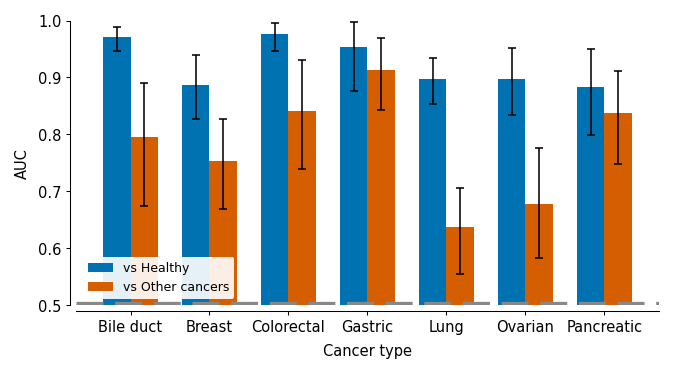

                              task   auc  ci_low  ci_high   n  n_pos
       Bile_duct_cancer_vs_healthy 0.971   0.947    0.988 285     25
 Bile_duct_cancer_vs_other_cancers 0.795   0.675    0.890 275     25
          Breast_cancer_vs_healthy 0.886   0.827    0.939 226     54
    Breast_cancer_vs_other_cancers 0.754   0.670    0.826 175     54
      Colorectal_cancer_vs_healthy 0.976   0.947    0.996 287     27
Colorectal_cancer_vs_other_cancers 0.842   0.739    0.930 275     27
         Gastric_cancer_vs_healthy 0.954   0.876    0.997 287     27
   Gastric_cancer_vs_other_cancers 0.912   0.843    0.969 275     27
            Lung_cancer_vs_healthy 0.897   0.853    0.935 339     79
      Lung_cancer_vs_other_cancers 0.637   0.555    0.706 275     79
         Ovarian_cancer_vs_healthy 0.898   0.834    0.951 199     27
   Ovarian_cancer_vs_other_cancers 0.677   0.583    0.775 175     27
      Pancreatic_cancer_vs_healthy 0.883   0.799    0.949 295     35
Pancreatic_cancer_vs_other_cancers

In [4]:
# ── Fig. 5c: per-cancer AUC bars ──────────────────────────────────────────────
# Per-task AUC table, computed here instead of read from cfdna_mil_auc_all_tasks_bootstrap.csv.
cancers = ['Bile_duct', 'Breast', 'Colorectal', 'Gastric', 'Lung', 'Ovarian', 'Pancreatic']
labels = ['Bile duct', 'Breast', 'Colorectal', 'Gastric', 'Lung', 'Ovarian', 'Pancreatic']
rows = []
for cancer in cancers:
    for comp in ['vs_healthy', 'vs_other_cancers']:
        task = f'{cancer}_cancer_{comp}'
        g = df[df['task'] == task]; y = g['label'].values; p = g['prob_ensemble'].values
        rng = np.random.default_rng(42); bs = []
        for _ in range(1000):
            i = rng.choice(len(y), size=len(y), replace=True)
            if len(np.unique(y[i])) < 2: continue
            bs.append(roc_auc_score(y[i], p[i]))
        rows.append(dict(cancer=cancer, comparison=comp, task=task, auc=roc_auc_score(y, p),
                         ci_low=np.percentile(bs, 2.5), ci_high=np.percentile(bs, 97.5), n=len(y), n_pos=int(y.sum())))
df_results = pd.DataFrame(rows)

x = np.arange(len(cancers)); width = 0.35
auc_h = []; err_h_low = []; err_h_high = []; auc_oc = []; err_oc_low = []; err_oc_high = []
for cancer in cancers:
    row_h = df_results[(df_results['cancer'] == cancer) & (df_results['comparison'] == 'vs_healthy')].iloc[0]
    auc_h.append(row_h['auc']); err_h_low.append(row_h['auc'] - row_h['ci_low']); err_h_high.append(row_h['ci_high'] - row_h['auc'])
    row_oc = df_results[(df_results['cancer'] == cancer) & (df_results['comparison'] == 'vs_other_cancers')].iloc[0]
    auc_oc.append(row_oc['auc']); err_oc_low.append(row_oc['auc'] - row_oc['ci_low']); err_oc_high.append(row_oc['ci_high'] - row_oc['auc'])
fig, ax = plt.subplots(figsize=(4.5, 2.5)); ax.axhline(0.5, color='#888888', linestyle='--', linewidth=3.5, zorder=3)
ax.bar(x - width / 2, auc_h, width, yerr=[err_h_low, err_h_high], capsize=2, color=OKABE_ITO['blue'], label='vs Healthy',
       edgecolor='none', error_kw={'linewidth': 0.75, 'capthick': 0.75}, zorder=2)
ax.bar(x + width / 2, auc_oc, width, yerr=[err_oc_low, err_oc_high], capsize=2, color=OKABE_ITO['orange'], label='vs Other cancers',
       edgecolor='none', error_kw={'linewidth': 0.75, 'capthick': 0.75}, zorder=2)
ax.set_xlabel('Cancer type'); ax.set_ylabel('AUC'); ax.set_xticks(x); ax.set_xticklabels(labels, rotation=30, ha='right'); ax.set_ylim(0.5, 1.0)
ax.legend(loc='lower left', frameon=True, fontsize=6, facecolor='white', edgecolor='none', framealpha=0.9)
ax.spines['left'].set_position(('outward', 3)); ax.spines['bottom'].set_position(('outward', 3)); ax.tick_params(axis='both', which='both', length=2, pad=2)
plt.tight_layout()
savefig(fig, OUT, 'cfdna_nocristiano_per_cancer_auc', data=df_results[['cancer', 'comparison', 'auc', 'ci_low', 'ci_high']])
plt.show()
print(df_results[['task', 'auc', 'ci_low', 'ci_high', 'n', 'n_pos']].round(3).to_string(index=False))

In [5]:
# ── Fig. 5g helpers (from cfdna_ctdna_detection.ipynb) ────────────────────────
from scipy.stats import wilcoxon

CANCERS = ["Bile_duct", "Breast", "Colorectal", "Gastric", "Lung", "Ovarian", "Pancreatic"]
COMPARISONS = ["vs_healthy", "vs_other_cancers"]
CTDNA_BIN_ORDER = ["low_ctDNA", "medium_ctDNA", "high_ctDNA"]
CTDNA_BIN_LABELS = {"low_ctDNA": "Low ctDNA", "medium_ctDNA": "Medium ctDNA", "high_ctDNA": "High ctDNA"}
LEAF1_COL = "prob_ensemble"

def _add_task_parts(frame):
    out = frame.copy(); out["cancer"] = pd.NA; out["comparison"] = pd.NA
    for c in CANCERS:
        for cmp in COMPARISONS:
            mask = out["task"] == f"{c}_cancer_{cmp}"
            out.loc[mask, "cancer"] = c; out.loc[mask, "comparison"] = cmp
    return out

def _fmt_p(pv):
    if pd.isna(pv): return "p=NA"
    return "p<0.001" if pv < 0.001 else f"p={pv:.3f}"

def _logit(prob, eps=1e-6):
    c = np.clip(np.asarray(prob, dtype=float), eps, 1 - eps)
    return np.log(c / (1 - c))

def _bsci(vals, n=10000, seed=42):
    a = pd.Series(vals, dtype="float64").dropna().to_numpy()
    if len(a) == 0: return np.nan, np.nan
    if len(a) == 1: return float(a[0]), float(a[0])
    rng = np.random.default_rng(seed)
    meds = np.median(rng.choice(a, size=(n, len(a)), replace=True), axis=1)
    return float(np.quantile(meds, 0.025)), float(np.quantile(meds, 0.975))

def _wilcoxon1(vals, null=0.0):
    a = pd.Series(vals, dtype="float64").dropna().to_numpy() - null
    if len(a) < 2: return np.nan
    if np.allclose(a, 0): return 1.0
    try: return float(wilcoxon(a).pvalue)
    except ValueError: return np.nan

def assign_bins(merged):
    # ichorCNA tertiles pooled over every cancer sample (the published notebook's default "tertile" method).
    pos = (
        merged[(merged["label"] == 1) & merged["ichorcna_tumor_fraction"].notna()]
        [["sample_id", "ichorcna_tumor_fraction"]].drop_duplicates("sample_id").copy()
    )
    try:
        pos["ctdna_bin"] = pd.qcut(pos["ichorcna_tumor_fraction"], q=3, labels=CTDNA_BIN_ORDER).astype("object")
    except ValueError:
        bins = pd.qcut(pos["ichorcna_tumor_fraction"], q=3, duplicates="drop")
        lmap = dict(zip(list(bins.cat.categories), CTDNA_BIN_ORDER[:len(bins.cat.categories)]))
        pos["ctdna_bin"] = bins.map(lmap).astype("object")
    return pos

# load_and_merge() equivalent: per-cancer tasks only; the tumor fraction is already in the table.
merged = _add_task_parts(df)
merged = merged[merged["cancer"].notna()].copy()
assignments = assign_bins(merged)
print(assignments["ctdna_bin"].value_counts().reindex(CTDNA_BIN_ORDER).to_string())

ctdna_bin
low_ctDNA       69
medium_ctDNA    69
high_ctDNA      69


saved: cfdna/output/cfdna_nocristiano_ctdna_logit_forest.pdf
saved: cfdna/output/cfdna_nocristiano_ctdna_logit_forest.png
saved: cfdna/output/cfdna_nocristiano_ctdna_logit_forest.svg
saved: cfdna/output/cfdna_nocristiano_ctdna_logit_forest.tsv


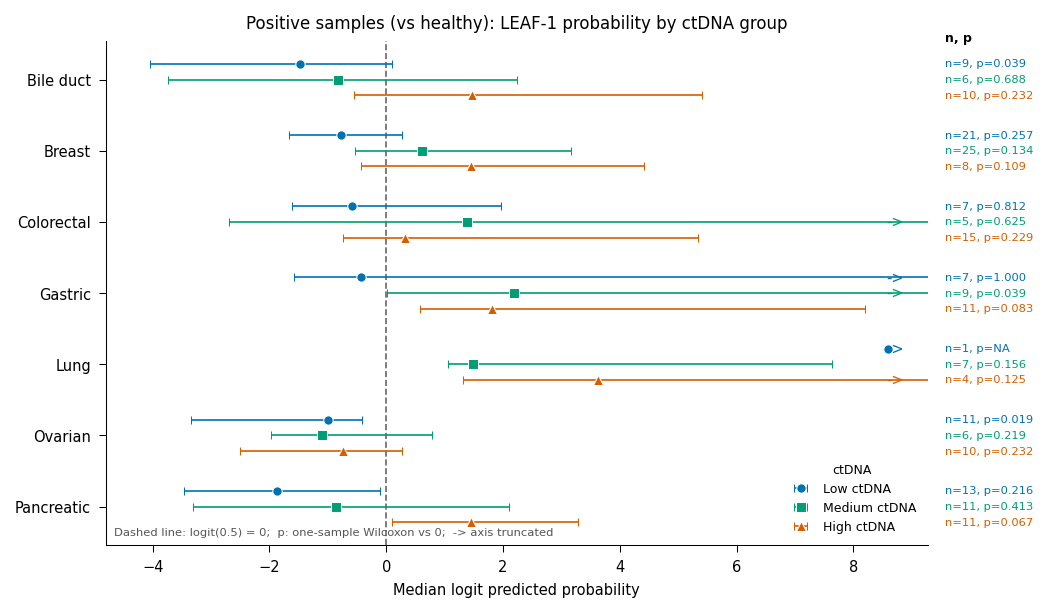

    cancer    ctdna_bin  n  median_logit  ci_low  ci_high p_label
 Bile_duct    low_ctDNA  9        -1.474  -4.051    0.104 p=0.039
 Bile_duct medium_ctDNA  6        -0.820  -3.734    2.231 p=0.688
 Bile_duct   high_ctDNA 10         1.461  -0.551    5.400 p=0.232
    Breast    low_ctDNA 21        -0.779  -1.663    0.273 p=0.257
    Breast medium_ctDNA 25         0.604  -0.529    3.157 p=0.134
    Breast   high_ctDNA  8         1.446  -0.439    4.419 p=0.109
Colorectal    low_ctDNA  7        -0.587  -1.619    1.972 p=0.812
Colorectal medium_ctDNA  5         1.375  -2.701   12.781 p=0.625
Colorectal   high_ctDNA 15         0.315  -0.744    5.331 p=0.229
   Gastric    low_ctDNA  7        -0.436  -1.579   11.393 p=1.000
   Gastric medium_ctDNA  9         2.194   0.004   13.816 p=0.039
   Gastric   high_ctDNA 11         1.814   0.581    8.193 p=0.083
      Lung    low_ctDNA  1         8.600   8.600    8.600    p=NA
      Lung medium_ctDNA  7         1.487   1.055    7.629 p=0.156
      Lung

In [6]:
# ── Fig. 5g: median logit probability by ctDNA group ──────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans', 'Helvetica'],
    'font.size': 7, 'axes.titlesize': 8, 'axes.labelsize': 7,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 6,
    'axes.linewidth': 0.5, 'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'lines.linewidth': 1, 'figure.dpi': 150, 'savefig.dpi': 600,
    'savefig.bbox': 'tight', 'axes.spines.top': False, 'axes.spines.right': False,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})

pos_preds = (
    merged[(merged["label"] == 1) & merged["ichorcna_tumor_fraction"].notna()].copy()
    .merge(assignments[["sample_id", "ctdna_bin"]], on="sample_id", how="left")
)

# Compute forest summary
sub = pos_preds[pos_preds["comparison"] == "vs_healthy"].copy()
rows = []
for ci, cancer in enumerate(CANCERS):
    for bi, b in enumerate(CTDNA_BIN_ORDER):
        one = sub[(sub["cancer"] == cancer) & (sub["ctdna_bin"] == b)]
        lp = pd.Series(_logit(one[LEAF1_COL]), index=one.index, dtype="float64")
        ci_lo, ci_hi = _bsci(lp, seed=42 + ci * 10 + bi)
        pv = _wilcoxon1(lp, null=0.0)
        rows.append({
            "cancer": cancer, "ctdna_bin": b, "n": len(one),
            "median_logit": float(lp.median()) if len(lp) > 0 else np.nan,
            "ci_low": ci_lo, "ci_high": ci_hi,
            "p_label": _fmt_p(pv),
        })
forest = pd.DataFrame(rows)

# Plot
offsets = {"low_ctDNA": -0.22, "medium_ctDNA": 0.0, "high_ctDNA": 0.22}
colors  = {"low_ctDNA": "#0072B2", "medium_ctDNA": "#009E73", "high_ctDNA": "#D55E00"}
markers = {"low_ctDNA": "o", "medium_ctDNA": "s", "high_ctDNA": "^"}
y_base  = np.arange(len(CANCERS))

all_fin = forest[["median_logit", "ci_low", "ci_high"]].to_numpy(dtype=float).ravel()
all_fin = all_fin[np.isfinite(all_fin)]
if len(all_fin) == 0: x_min, x_hi = -1.0, 1.0
else:
    x_min = float(np.min(all_fin))
    x_hi  = float(np.percentile(all_fin, 90))
    if np.isclose(x_min, x_hi): x_min -= 0.5; x_hi += 0.5
x_pad = max(0.3, (x_hi - x_min) * 0.06)
label_x = x_hi + x_pad * 1.4

fig, ax = plt.subplots(figsize=(7.0, 4.1))
ax.axvline(0, color='#666666', linestyle='--', linewidth=0.8, zorder=1)
ax.text(label_x, -0.58, 'n, p', ha='left', va='center', fontsize=6, fontweight='bold', clip_on=False)

for b in CTDNA_BIN_ORDER:
    one = forest[forest["ctdna_bin"] == b].set_index("cancer").reindex(CANCERS)
    y  = y_base + offsets[b]
    xv = one["median_logit"].to_numpy(dtype=float)
    xerr = np.vstack([xv - one["ci_low"].to_numpy(dtype=float),
                      one["ci_high"].to_numpy(dtype=float) - xv])
    ax.errorbar(xv, y, xerr=xerr, fmt=markers[b], markersize=4.5, capsize=2,
                elinewidth=0.8, markeredgewidth=0.5, color=colors[b],
                markeredgecolor='white', label=CTDNA_BIN_LABELS[b],
                linestyle='none', zorder=3)
    for yi, xi, chi, nv, pl in zip(y, xv, one['ci_high'].to_numpy(dtype=float),
                                    one['n'], one['p_label']):
        if np.isfinite(chi) and chi > x_hi or (np.isfinite(xi) and xi > x_hi):
            ax.text(x_hi + 0.05, yi, '->', ha='left', va='center',
                    fontsize=7, color=colors[b], clip_on=False)
        if pd.notna(nv):
            ax.text(label_x, yi, f'n={int(nv)}, {pl}', ha='left', va='center',
                    fontsize=5.5, color=colors[b], clip_on=False)

ax.set_yticks(y_base)
ax.set_yticklabels([c.replace('_', ' ') for c in CANCERS])
ax.invert_yaxis()
ax.set_xlim(x_min - x_pad, x_hi + x_pad)
ax.set_xlabel('Median logit predicted probability')
ax.set_title('Positive samples (vs healthy): LEAF-1 probability by ctDNA group', fontsize=8)
ax.text(0.01, 0.02,
        'Dashed line: logit(0.5) = 0;  p: one-sample Wilcoxon vs 0;  -> axis truncated',
        transform=ax.transAxes, fontsize=5.5, color='#555555')
ax.legend(frameon=False, fontsize=6, title='ctDNA', title_fontsize=6, loc='lower right')
fig.tight_layout()
savefig(fig, OUT, 'cfdna_nocristiano_ctdna_logit_forest', data=(forest))
plt.show()
print(forest.round(3).to_string(index=False))